# Microscopy Denoising / reconstruction

Workflow for multi-channel images acquired as z-stacks.


---

In [1]:
# =============================================================================
# IMPORTS
# =============================================================================
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.patheffects as pe
import seaborn as sns
from pathlib import Path

from skimage import io
from skimage.util import img_as_float
from skimage.morphology import disk, white_tophat
from skimage import restoration
from skimage.filters import gaussian
from skimage.exposure import rescale_intensity
from scipy.ndimage import gaussian_filter
from scipy.interpolate import UnivariateSpline
from skimage.restoration import rolling_ball

# Global seaborn style
sns.set_theme(style="ticks", context="notebook", font_scale=1.05)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# =============================================================================
# SCALE BAR UTILITY — universal, auto-sizing, publication-grade
#
# Usage:
#   add_scalebar(ax, px_per_um)                    # auto bar length
#   add_scalebar(ax, px_per_um, bar_um=20)         # force 20 µm
#   add_scalebar(ax, px_per_um * UPSCALE_FACTOR)   # after SR ×4
#
# Rules for px_per_um:
#   Full frame (512 px)    → SCALE_PX_PER_UM
#   ROI crop (160 px)      → SCALE_PX_PER_UM        (crop ≠ resize)
#   EDSR ×4 full frame     → SCALE_PX_PER_UM * 4
#   EDSR ×4 ROI            → SCALE_PX_PER_UM * 4
#   Any sub-detail crop    → same as its parent image (no resize)
# =============================================================================

def add_scalebar(
    ax,
    px_per_um:   float,
    bar_um:      float  = None,   # µm length; None = auto-pick
    position:    str    = "br",   # "br" bottom-right | "bl" bottom-left
    margin_frac: float  = 0.04,   # margin as fraction of image width
    bar_h_frac:  float  = 0.008,  # bar height as fraction of image height
    color:       str    = "white",
    fontsize:    float  = None,   # None = auto-scale with image size
    box_alpha:   float  = 0.0,   # background box opacity (0=off)
    label:       str    = None,   # None = auto "XX µm"
):
    """
    Draw a physical scale bar on a Matplotlib axes.

    The bar length in pixels is computed dynamically from the axes extent
    so it works correctly on:
      - full frames        (512 px, standard calibration)
      - ROI crops          (same px_per_um, different size)
      - super-resolved     (px_per_um × upscale_factor)
      - any sub-detail     (same px_per_um as parent crop)

    Auto-sizing picks the largest "nice" bar that fits in ~25% of image width.
    """
    import matplotlib.patches as patches
    import matplotlib.patheffects as pe
    import numpy as np

    # ── Image extent from axes ───────────────────────────────────────────────
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    img_w_px = abs(xlim[1] - xlim[0])   # in image-data pixels
    img_h_px = abs(ylim[1] - ylim[0])

    # ── Auto-pick bar length (largest "round" value ≤ 25% of image width) ───
    if bar_um is None:
        nice_vals = [2, 5, 10, 20, 25, 50, 100, 150, 200]
        max_um    = img_w_px * 0.25 / px_per_um
        bar_um    = max((v for v in nice_vals if v <= max_um), default=nice_vals[0])

    bar_px    = bar_um * px_per_um
    margin_px = margin_frac * img_w_px
    bar_h_px  = max(bar_h_frac * img_h_px, 2.0)   # minimum 2 data-px tall

    # ── Position ─────────────────────────────────────────────────────────────
    if "r" in position:
        x_bar_right = (xlim[1] if xlim[1] > xlim[0] else xlim[0]) - margin_px
        x_bar_left  = x_bar_right - bar_px
    else:
        x_bar_left  = (xlim[0] if xlim[0] < xlim[1] else xlim[1]) + margin_px
        x_bar_right = x_bar_left + bar_px

    # y: images in matplotlib have y=0 at top, ylim[0] > ylim[1] (inverted)
    y_bottom = max(ylim) - margin_px           # "bottom" = large y value
    y_top    = y_bottom - bar_h_px

    x_center = (x_bar_left + x_bar_right) / 2.0
    y_text   = y_top - bar_h_px * 0.6         # text just above bar

    # ── Auto font size ────────────────────────────────────────────────────────
    if fontsize is None:
        # Scale with image width: ~9 pt for 512 px, ~7 pt for 160 px, ~11 pt for 2048
        fontsize = max(6.5, min(13, 9 * (img_w_px / 512) ** 0.45))

    label_str = label if label is not None else f"{int(bar_um)} µm"
    stroke    = [pe.withStroke(linewidth=max(1.5, fontsize * 0.18),
                               foreground="black")]

    # ── Optional translucent background box ───────────────────────────────────
    if box_alpha > 0:
        pad = margin_px * 0.4
        ax.add_patch(patches.FancyBboxPatch(
            (x_bar_left - pad, y_text - bar_h_px * 2.5),
            bar_px + 2 * pad,
            bar_h_px * 4.5,
            boxstyle="round,pad=0",
            facecolor="black", edgecolor="none",
            alpha=box_alpha, zorder=8,
        ))

    # ── Scale bar rectangle ───────────────────────────────────────────────────
    ax.add_patch(patches.Rectangle(
        (x_bar_left, y_top), bar_px, bar_h_px,
        facecolor=color, edgecolor="black",
        linewidth=max(0.5, fontsize * 0.06),
        zorder=9,
    ))

    # ── Label ─────────────────────────────────────────────────────────────────
    ax.text(
        x_center, y_text,
        label_str,
        color=color,
        fontsize=fontsize,
        fontweight="bold",
        ha="center", va="bottom",
        path_effects=stroke,
        zorder=10,
    )


# =============================================================================
# QUICK REFERENCE — copy-paste for each figure type
# =============================================================================
#
#   Full frame (512×512):
#       add_scalebar(ax, SCALE_PX_PER_UM)                    # auto → 50 µm
#       add_scalebar(ax, SCALE_PX_PER_UM, bar_um=50)
#
#   ROI crop (160×160 px, no resize → same calibration):
#       add_scalebar(ax, SCALE_PX_PER_UM)                    # auto → 20 µm
#       add_scalebar(ax, SCALE_PX_PER_UM, bar_um=20)
#
#   SR full frame (2048×2048, EDSR ×4):
#       add_scalebar(ax, SCALE_PX_PER_UM * UPSCALE_FACTOR)   # auto → 50 µm
#
#   SR ROI (640×640, EDSR ×4):
#       add_scalebar(ax, SCALE_PX_PER_UM * UPSCALE_FACTOR)   # auto → 20 µm
#
#   Sub-detail crop from ROI (no resize):
#       add_scalebar(ax, SCALE_PX_PER_UM)                    # auto → 10 µm
#
#   Bottom-left placement:
#       add_scalebar(ax, SCALE_PX_PER_UM, position="bl")
#
# =============================================================================


Extracting slice Z=14...
Channels loaded: 3 — shape: (512, 512)


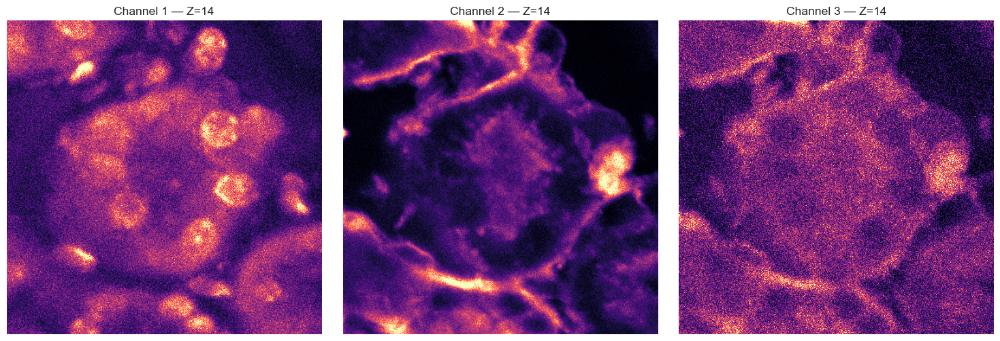

In [3]:
# =============================================================================
# CONFIGURATION — adjust paths and parameters to your dataset
# =============================================================================
CONFIG = {
    "folder_path": "/Users/francesco/Repositories/1.sem/noise_images/immk",
    "file_ch1": "/Users/francesco/Repositories/1.sem/noise_images/immk/rat_19_12_770nm_25mW_stack_16slices_width_30mum_zoomed_Ch1.tif",
    "file_ch2": "/Users/francesco/Repositories/1.sem/noise_images/immk/rat_19_12_770nm_25mW_stack_16slices_width_30mum_zoomed_Ch2.tif",
    "file_ch3": "/Users/francesco/Repositories/1.sem/noise_images/immk/rat_19_12_770nm_25mW_stack_16slices_width_30mum_zoomed_Ch3.tif",
    "channel_names": ["Channel 1", "Channel 2", "Channel 3"],
    "z_target": 13,         # Python index → corresponds to Z=12/50
    "cmap": "magma",
}

# Physical calibration (from ImageJ)
DIST_PX         = 109.0046
DIST_UM         = 31.94
PX_SIZE_UM      = DIST_UM / DIST_PX       # ~0.293 µm/px
SCALE_PX_PER_UM = DIST_PX / DIST_UM       # ~3.41 px/µm

# Pipeline parameters
PARAMS = dict(
    nlm_h          = 0.80,   # NLM filter strength (sigma multiplier)
    tophat_r       = 40,     # White Top-Hat footprint radius (px)
    gauss_bg_sigma = 20,     # Gaussian Subtraction sigma for background estimate
    rl_iters       = 15,     # Richardson-Lucy iterations (see Phase 3 note)
    psf_sigma      = 1.5,    # Gaussian PSF sigma (px)
    psf_size       = 51,     # PSF kernel size (px, must be odd)
)

# =============================================================================
# LOAD Z-STACK AND EXTRACT SLICE Z=12 — all 3 channels
# =============================================================================
os.chdir(CONFIG["folder_path"])

raw_channels = []   # list of 2D float slices, normalised [0, 1]

print(f"Extracting slice Z={CONFIG['z_target'] + 1}...")

for fname in [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]:
    p = Path(fname)
    if not p.exists():
        raise FileNotFoundError(f"File not found: {p.absolute()}")
    stack = io.imread(p)
    sl = stack[CONFIG["z_target"], :, :] if stack.ndim == 3 else stack
    raw_channels.append(img_as_float(sl))

print(f"Channels loaded: {len(raw_channels)} — shape: {raw_channels[0].shape}")

# Working reference: Channel 1
raw = raw_channels[0]

# Quick overview — all 3 channels
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, name in zip(axes, raw_channels, CONFIG["channel_names"]):
    ax.imshow(img, cmap=CONFIG["cmap"], vmax=np.percentile(img, 99.5))
    ax.set_title(f"{name} — Z={CONFIG['z_target'] + 1}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("00_raw_channels.pdf", bbox_inches="tight", facecolor="white")
plt.show()
plt.close("all")

---
## Phase 1 — Deconvolution (Richardson-Lucy)

Deconvolution inverts the effect of the optical **PSF (Point Spread Function)**,
upgrading from *Pure Denoising* to *Denoised Deconvolution*.

**Richardson-Lucy (R-L)** is an iterative Bayesian algorithm, statistically optimal for
Poisson noise:

$$x^{(k+1)} = x^{(k)} \cdot \left[ h^* \ast \frac{y}{h \ast x^{(k)}} \right]$$

where `h` is the PSF, `y` the observed image, and `*` denotes convolution.

> **⚠️ Iteration count `rl_iters`:**
> R-L is semi-convergent: too few → under-correction (residual blur);
> too many → **noise amplification**, ringing artefacts, and divergence.
> Typical range for microscopy: **10–30 iterations**. Tune empirically.

**PSF model:** a **Gaussian PSF** is used as a practical approximation of the central lobe
of the Airy function. For metric applications (e.g. physical FWHM) it can be replaced
by a Born-Wolf model.

---
## Cell Zoom

Raw vs final output on a cropped ROI centred on a nucleus:
sharpening improvements and background suppression become clearly visible.

loaded z=12 from disk
input shape: (512, 512), range: [0.0000, 0.0028]
denoising and background removal...
calculating psf...
running richardson-lucy...
saved to /Users/francesco/Repositories/noise_images/immagini_rel/completo_iterazioni.png


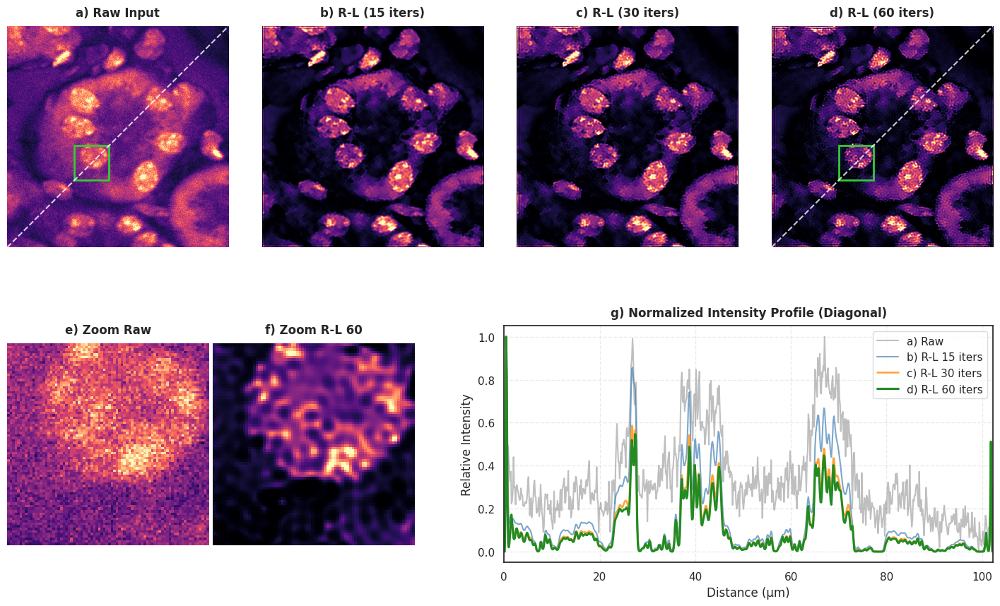

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from skimage import img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.exposure import rescale_intensity
from skimage.io import imread
from skimage.measure import profile_line
from scipy.special import j0

try:
    from numpy import trapezoid
except ImportError:
    from numpy import trapz as trapezoid

# config
MICROSCOPE = dict(NA=0.8, wavelength=0.770, ni=1.000, pixel_size=0.100)

PARAMS = dict(
    nlm_h_factor     = 0.80,
    nlm_patch        = 5,
    nlm_dist         = 6,
    tophat_radius    = 40,
    psf_size         = 51,
    psf_n_samples    = 256,
    rl_epsilon       = 1e-6,
    cmap             = "magma",
    # roi shiftata in basso a sx lungo la diagonale y = 511 - x
    # Centro (y=316, x=195), raggio=40
    roi              = (276, 356, 155, 235),
    # coordinate linea diagonale (y, x)
    profile_src      = (511, 0),
    profile_dst      = (0, 511),
)

# utils
def _anscombe(img):
    return 2.0 * np.sqrt(np.maximum(img, 0) + 3.0 / 8.0)

def _inv_anscombe(img):
    return np.maximum((img / 2.0) ** 2 - 3.0 / 8.0, 0)

def _norm_percentile(img, lo=0.1, hi=99.9):
    vmin, vmax = np.percentile(img, lo), np.percentile(img, hi)
    return rescale_intensity(img, in_range=(vmin, vmax), out_range=(0.0, 1.0))

def _scale_for_plot(arr):
    return (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)

def make_born_wolf_psf(p: dict, size: int, n_samples: int) -> np.ndarray:
    k = 2 * np.pi * p["ni"] / p["wavelength"]
    ax = (np.arange(size) - size // 2) * p["pixel_size"]
    rho = np.linspace(0, 1, n_samples)
    psf = np.zeros((size, size))
    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r = np.sqrt(x**2 + y**2)
            integrand = j0(k * p["NA"] * r * rho / p["ni"]) * rho
            psf[i, j] = trapezoid(integrand, rho) ** 2
    return psf / psf.sum()

# load
IMAGE_PATH = "/Users/francesco/Repositories/1.sem/noise_images/immk/rat_19_12_770nm_25mW_stack_16slices_width_30mum_zoomed_Ch1.tif"

if IMAGE_PATH and os.path.isfile(IMAGE_PATH):
    stack = imread(IMAGE_PATH)
    raw = img_as_float(stack[11, :, :])
    print("loaded z=12 from disk")
else:
    print("file not found, generating mock data...")
    np.random.seed(42)
    y_grid, x_grid = np.mgrid[0:512, 0:512]
    raw = np.zeros((512, 512))
    for _ in range(60):
        cy, cx = np.random.randint(50, 460, 2)
        r = np.random.uniform(3, 8)
        raw += np.exp(-((x_grid - cx)**2 + (y_grid - cy)**2) / (2 * r**2))
    raw = rescale_intensity(raw, out_range=(0.1, 0.7))
    raw = np.random.poisson(raw * 50) / 50.0
    raw += np.random.normal(0, 0.05, raw.shape)
    raw = np.clip(raw, 0, 1)

print(f"input shape: {raw.shape}, range: [{raw.min():.4f}, {raw.max():.4f}]")

# pre-processing
print("denoising and background removal...")
img_ansc = _anscombe(raw)
sigma_est = float(np.mean(restoration.estimate_sigma(img_ansc)))
img_nlm = restoration.denoise_nl_means(
    img_ansc, h=PARAMS["nlm_h_factor"] * sigma_est, fast_mode=True,
    patch_size=PARAMS["nlm_patch"], patch_distance=PARAMS["nlm_dist"]
)
img_denoised = np.clip(_inv_anscombe(img_nlm), 0, None)
img_bg_removed = white_tophat(img_denoised, disk(PARAMS["tophat_radius"]))
img_clean = np.clip(img_bg_removed, 0, None)

# deconvolution
print("calculating psf...")
psf = make_born_wolf_psf(MICROSCOPE, size=PARAMS["psf_size"], n_samples=PARAMS["psf_n_samples"])

print("running richardson-lucy...")
img_deconv_15 = restoration.richardson_lucy(img_clean, psf, num_iter=15, filter_epsilon=PARAMS["rl_epsilon"])
img_final_15 = _norm_percentile(img_deconv_15)

img_deconv_30 = restoration.richardson_lucy(img_clean, psf, num_iter=30, filter_epsilon=PARAMS["rl_epsilon"])
img_final_30 = _norm_percentile(img_deconv_30)

img_deconv_60 = restoration.richardson_lucy(img_clean, psf, num_iter=60, filter_epsilon=PARAMS["rl_epsilon"])
img_final_60 = _norm_percentile(img_deconv_60)

# plotting
sns.set_theme(style="white", context="notebook", palette="deep")
fig = plt.figure(figsize=(18, 10))
gs_main = fig.add_gridspec(2, 1, hspace=0.3)

# main comparisons
gs_row0 = gs_main[0].subgridspec(1, 4, wspace=0.15)
stages = [
    (raw,          "a) Raw Input"),
    (img_final_15, "b) R-L (15 iters)"),
    (img_final_30, "c) R-L (30 iters)"),
    (img_final_60, "d) R-L (60 iters)"),
]

axes_pipe = [fig.add_subplot(gs_row0[i]) for i in range(4)]
y0, y1, x0, x1 = PARAMS["roi"]
p_src = PARAMS["profile_src"]
p_dst = PARAMS["profile_dst"]
pixel_size = MICROSCOPE["pixel_size"]

for i, (ax, (img, title)) in enumerate(zip(axes_pipe, stages)):
    ax.imshow(img, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(img, 99.5))
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.axis("off")
    
    # highlight roi and diagonal on first and last img
    if i in [0, 3]:
        rect = patches.Rectangle((x0, y0), x1 - x0, y1 - y0, 
                                 linewidth=2, edgecolor='limegreen', 
                                 facecolor='none', linestyle='-')
        ax.add_patch(rect)
        ax.plot([p_src[1], p_dst[1]], [p_src[0], p_dst[0]], 
                color='white', linewidth=1.5, linestyle='--', alpha=0.8)

# zooms and profiles
gs_row1 = gs_main[1].subgridspec(1, 2, width_ratios=[1, 1.2], wspace=0.2)
gs_zooms = gs_row1[0].subgridspec(1, 2, wspace=0.02)

ax_zraw = fig.add_subplot(gs_zooms[0])
ax_zfin = fig.add_subplot(gs_zooms[1])
ax_prof = fig.add_subplot(gs_row1[1])

crop_raw = raw[y0:y1, x0:x1]
ax_zraw.imshow(crop_raw, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(crop_raw, 99.5))
ax_zraw.set_title("e) Zoom Raw", fontsize=12, fontweight="bold", pad=10)
ax_zraw.axis("off")

crop_final = img_final_60[y0:y1, x0:x1]
ax_zfin.imshow(crop_final, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(crop_final, 99.5))
ax_zfin.set_title("f) Zoom R-L 60", fontsize=12, fontweight="bold", pad=10)
ax_zfin.axis("off")

# extract intensity along the diagonal
prof_raw = profile_line(raw, p_src, p_dst)
prof_15  = profile_line(img_final_15, p_src, p_dst)
prof_30  = profile_line(img_final_30, p_src, p_dst)
prof_60  = profile_line(img_final_60, p_src, p_dst)

# x axis in micrometers
asse_x_um = np.arange(len(prof_raw)) * pixel_size * np.sqrt(2)

ax_prof.plot(asse_x_um, _scale_for_plot(prof_raw), color="gray",        alpha=0.5, lw=1.5, label="a) Raw")
ax_prof.plot(asse_x_um, _scale_for_plot(prof_15),  color="steelblue",   alpha=0.7, lw=1.5, label="b) R-L 15 iters")
ax_prof.plot(asse_x_um, _scale_for_plot(prof_30),  color="darkorange",  alpha=0.8, lw=1.8, label="c) R-L 30 iters")
ax_prof.plot(asse_x_um, _scale_for_plot(prof_60),  color="forestgreen", alpha=1.0, lw=2.2, label="d) R-L 60 iters")

ax_prof.set_title("g) Normalized Intensity Profile (Diagonal)", fontsize=12, fontweight="bold", pad=10)
ax_prof.set_xlabel("Distance (µm)")
ax_prof.set_ylabel("Relative Intensity")
ax_prof.legend(frameon=True, facecolor="white", edgecolor="lightgray")
ax_prof.grid(True, alpha=0.4, linestyle="--")
ax_prof.margins(x=0)

sns.reset_orig()

# export
out_dir = "/Users/francesco/Repositories/noise_images/immagini_rel"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "completo_iterazioni.png")

plt.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"saved to {out_path}")

plt.show()

image_final_hr = img_final_60

### fare il discorso sulle iterazioni e scegliere un numero di iterazioni buono 


## Phase 2: AGGIUNGIAMO IL SECONDO METODO: denoise_wavelet

loaded z=12 from disk
input shape: (512, 512), range: [0.0000, 0.0028]
denoising and background removal for R-L...
running wavelet denoising...
calculating psf and running richardson-lucy...
saved to /Users/francesco/Repositories/noise_images/immagini_rel/confronto_wavelet_rl30.png


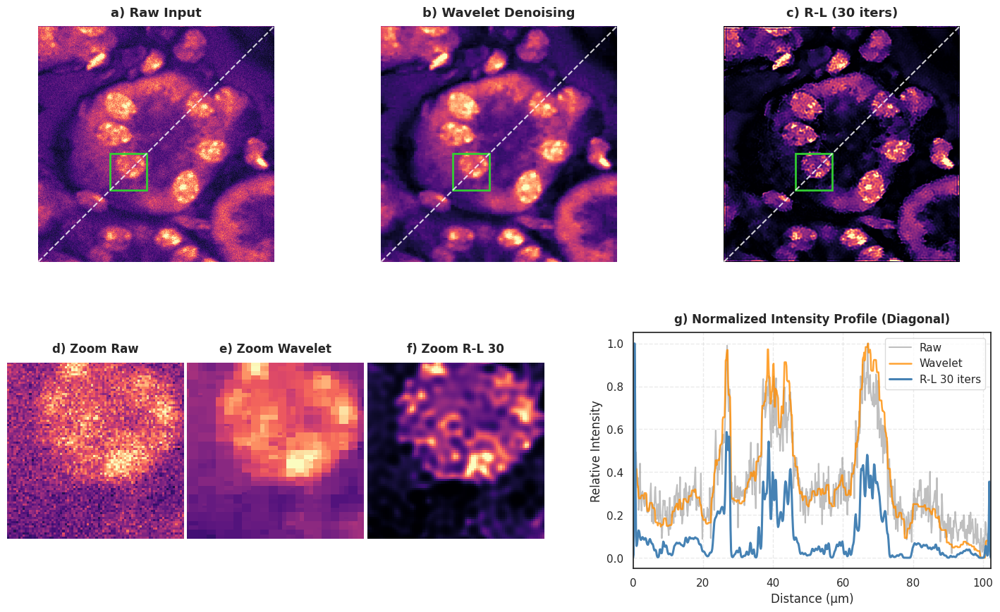

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from skimage import img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.exposure import rescale_intensity
from skimage.io import imread
from skimage.measure import profile_line
from scipy.special import j0

try:
    from numpy import trapezoid
except ImportError:
    from numpy import trapz as trapezoid

# config
MICROSCOPE = dict(NA=0.8, wavelength=0.770, ni=1.000, pixel_size=0.100)

PARAMS = dict(
    nlm_h_factor     = 0.80,
    nlm_patch        = 5,
    nlm_dist         = 6,
    tophat_radius    = 40,
    psf_size         = 51,
    psf_n_samples    = 256,
    rl_epsilon       = 1e-6,
    cmap             = "magma",
    # roi shiftata in basso a sx lungo la diagonale y = 511 - x
    # Centro (y=316, x=195), raggio=40
    roi              = (276, 356, 155, 235),
    # coordinate linea diagonale (y, x)
    profile_src      = (511, 0),
    profile_dst      = (0, 511),
)

# utils
def _anscombe(img):
    return 2.0 * np.sqrt(np.maximum(img, 0) + 3.0 / 8.0)

def _inv_anscombe(img):
    return np.maximum((img / 2.0) ** 2 - 3.0 / 8.0, 0)

def _norm_percentile(img, lo=0.1, hi=99.9):
    vmin, vmax = np.percentile(img, lo), np.percentile(img, hi)
    return rescale_intensity(img, in_range=(vmin, vmax), out_range=(0.0, 1.0))

def _scale_for_plot(arr):
    return (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)

def make_born_wolf_psf(p: dict, size: int, n_samples: int) -> np.ndarray:
    k = 2 * np.pi * p["ni"] / p["wavelength"]
    ax = (np.arange(size) - size // 2) * p["pixel_size"]
    rho = np.linspace(0, 1, n_samples)
    psf = np.zeros((size, size))
    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r = np.sqrt(x**2 + y**2)
            integrand = j0(k * p["NA"] * r * rho / p["ni"]) * rho
            psf[i, j] = trapezoid(integrand, rho) ** 2
    return psf / psf.sum()

# load
IMAGE_PATH = "/Users/francesco/Repositories/1.sem/noise_images/immk/rat_19_12_770nm_25mW_stack_16slices_width_30mum_zoomed_Ch1.tif"

if IMAGE_PATH and os.path.isfile(IMAGE_PATH):
    stack = imread(IMAGE_PATH)
    raw = img_as_float(stack[11, :, :])
    print("loaded z=12 from disk")
else:
    print("file not found, generating mock data...")
    np.random.seed(42)
    y_grid, x_grid = np.mgrid[0:512, 0:512]
    raw = np.zeros((512, 512))
    for _ in range(60):
        cy, cx = np.random.randint(50, 460, 2)
        r = np.random.uniform(3, 8)
        raw += np.exp(-((x_grid - cx)**2 + (y_grid - cy)**2) / (2 * r**2))
    raw = rescale_intensity(raw, out_range=(0.1, 0.7))
    raw = np.random.poisson(raw * 50) / 50.0
    raw += np.random.normal(0, 0.05, raw.shape)
    raw = np.clip(raw, 0, 1)

print(f"input shape: {raw.shape}, range: [{raw.min():.4f}, {raw.max():.4f}]")

# pre-processing for R-L
print("denoising and background removal for R-L...")
img_ansc = _anscombe(raw)
sigma_est = float(np.mean(restoration.estimate_sigma(img_ansc)))
img_nlm = restoration.denoise_nl_means(
    img_ansc, h=PARAMS["nlm_h_factor"] * sigma_est, fast_mode=True,
    patch_size=PARAMS["nlm_patch"], patch_distance=PARAMS["nlm_dist"]
)
img_denoised = np.clip(_inv_anscombe(img_nlm), 0, None)
img_bg_removed = white_tophat(img_denoised, disk(PARAMS["tophat_radius"]))
img_clean = np.clip(img_bg_removed, 0, None)

# processing: Wavelet
print("running wavelet denoising...")
img_wavelet_raw = restoration.denoise_wavelet(raw, method='BayesShrink', mode='soft', rescale_sigma=True)
img_wavelet = _norm_percentile(img_wavelet_raw)

# processing: R-L 30 iter
print("calculating psf and running richardson-lucy...")
psf = make_born_wolf_psf(MICROSCOPE, size=PARAMS["psf_size"], n_samples=PARAMS["psf_n_samples"])
img_deconv_30 = restoration.richardson_lucy(img_clean, psf, num_iter=30, filter_epsilon=PARAMS["rl_epsilon"])
img_final_30 = _norm_percentile(img_deconv_30)

# plotting
sns.set_theme(style="white", context="notebook", palette="deep")
fig = plt.figure(figsize=(18, 10))
gs_main = fig.add_gridspec(2, 1, hspace=0.3)

# main comparisons (3 columns now)
gs_row0 = gs_main[0].subgridspec(1, 3, wspace=0.15)
stages = [
    (raw,          "a) Raw Input"),
    (img_wavelet,  "b) Wavelet Denoising"),
    (img_final_30, "c) R-L (30 iters)"),
]

axes_pipe = [fig.add_subplot(gs_row0[i]) for i in range(3)]
y0, y1, x0, x1 = PARAMS["roi"]
p_src = PARAMS["profile_src"]
p_dst = PARAMS["profile_dst"]
pixel_size = MICROSCOPE["pixel_size"]

for ax, (img, title) in zip(axes_pipe, stages):
    ax.imshow(img, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(img, 99.5))
    ax.set_title(title, fontsize=13, fontweight="bold", pad=10)
    ax.axis("off")
    
    # highlight roi and diagonal on all imgs
    rect = patches.Rectangle((x0, y0), x1 - x0, y1 - y0, 
                             linewidth=2, edgecolor='limegreen', 
                             facecolor='none', linestyle='-')
    ax.add_patch(rect)
    ax.plot([p_src[1], p_dst[1]], [p_src[0], p_dst[0]], 
            color='white', linewidth=1.5, linestyle='--', alpha=0.8)

# zooms and profiles
# split the bottom row: 1.5 width for the 3 zooms, 1.0 width for the profile
gs_row1 = gs_main[1].subgridspec(1, 2, width_ratios=[1.5, 1], wspace=0.2)
gs_zooms = gs_row1[0].subgridspec(1, 3, wspace=0.02)

ax_zraw = fig.add_subplot(gs_zooms[0])
ax_zwav = fig.add_subplot(gs_zooms[1])
ax_zfin = fig.add_subplot(gs_zooms[2])
ax_prof = fig.add_subplot(gs_row1[1])

# crops
crops = [
    (raw[y0:y1, x0:x1], ax_zraw, "d) Zoom Raw"),
    (img_wavelet[y0:y1, x0:x1], ax_zwav, "e) Zoom Wavelet"),
    (img_final_30[y0:y1, x0:x1], ax_zfin, "f) Zoom R-L 30"),
]

for crop_img, ax_z, title in crops:
    ax_z.imshow(crop_img, cmap=PARAMS["cmap"], vmin=0, vmax=np.percentile(crop_img, 99.5))
    ax_z.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax_z.axis("off")

# extract intensity along the diagonal
prof_raw = profile_line(raw, p_src, p_dst)
prof_wav = profile_line(img_wavelet, p_src, p_dst)
prof_30  = profile_line(img_final_30, p_src, p_dst)

# x axis in micrometers
asse_x_um = np.arange(len(prof_raw)) * pixel_size * np.sqrt(2)

ax_prof.plot(asse_x_um, _scale_for_plot(prof_raw), color="gray",       alpha=0.5, lw=1.5, label="Raw")
ax_prof.plot(asse_x_um, _scale_for_plot(prof_wav), color="darkorange", alpha=0.8, lw=1.8, label="Wavelet")
ax_prof.plot(asse_x_um, _scale_for_plot(prof_30),  color="steelblue",  alpha=1.0, lw=2.2, label="R-L 30 iters")

ax_prof.set_title("g) Normalized Intensity Profile (Diagonal)", fontsize=12, fontweight="bold", pad=10)
ax_prof.set_xlabel("Distance (µm)")
ax_prof.set_ylabel("Relative Intensity")
ax_prof.legend(frameon=True, facecolor="white", edgecolor="lightgray")
ax_prof.grid(True, alpha=0.4, linestyle="--")
ax_prof.margins(x=0)

sns.reset_orig()

# export
out_dir = "/Users/francesco/Repositories/noise_images/immagini_rel"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "confronto_wavelet_rl30.png")

plt.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"saved to {out_path}")

plt.show()

image_final_hr = img_final_30

---
## Phase 3: Quantitative Evaluation — SNR, CNR, FWHM

Numerical comparison across pipeline stages on 3 physical metrics:
- **SNR** = μ_signal / σ_background
- **CNR** = |μ_signal − μ_background| / σ_background
- **FWHM** (µm): half-maximum width of the intensity profile on a selected nucleus
IL GRAFICO FWHM SI PUO ANCHE OMETTERE
Signal (green) and background (white) ROIs are drawn directly on the images.

saved to /Users/francesco/Repositories/noise_images/immagini_rel/SNR_con_wavelet.png


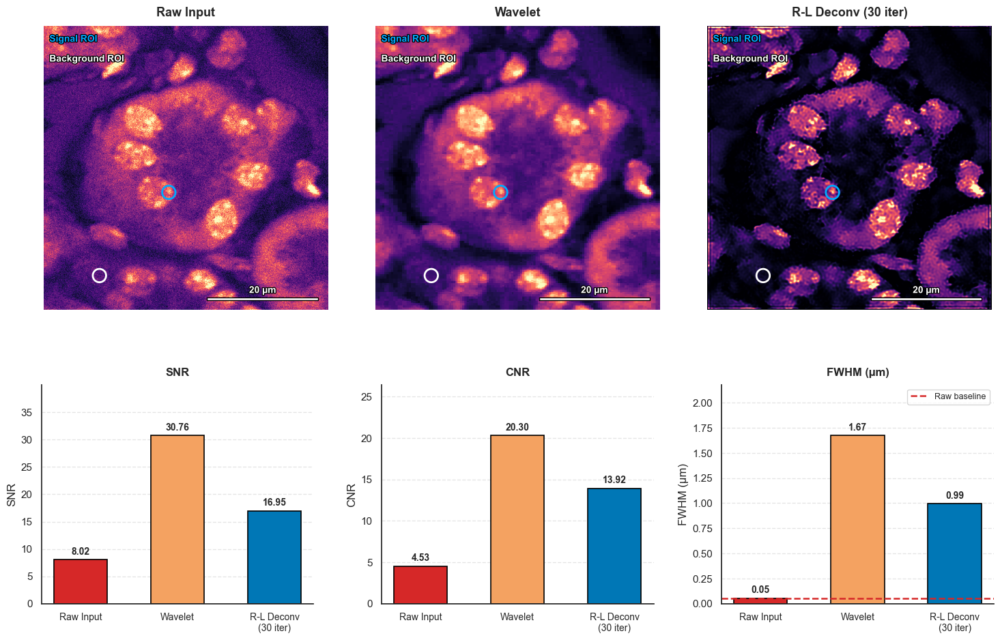

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.patheffects as pe
import seaborn as sns
from scipy.interpolate import UnivariateSpline
from skimage import restoration

# =============================================================================
# WAVELET DENOISING (se non già calcolato nella cella)
# =============================================================================
# Usa la funzione di utilità _norm_percentile definita in precedenza
img_wavelet_raw = restoration.denoise_wavelet(raw, method='BayesShrink', mode='soft', rescale_sigma=True)
img_wavelet = _norm_percentile(img_wavelet_raw)

# =============================================================================
# METRICS CONFIG
# =============================================================================
PX_SIZE_UM = MICROSCOPE["pixel_size"]
SCALE_PX_PER_UM = 1.0 / PX_SIZE_UM

# Valutiamo raw, wavelet e rl a 30 iterazioni
risultati = {
    "Raw Input": raw,
    "Wavelet": img_wavelet,
    "R-L Deconv (30 iter)": img_final_30
}
labels = list(risultati.keys())

# coordinate rois (centro circolare y, x) e raggio
Y_SIG, X_SIG = 300, 225  # Nucleo centrale/luminoso
Y_BG,  X_BG  = 450, 100  # Fondo scuro in basso a sinistra
ROI_RADIUS   = 12

def calculate_local_fwhm(img, y, x, window=40):
    start   = max(0, x - window)
    end     = min(img.shape[1], x + window)
    profile = img[y, start:end] - img[y, start:end].min()
    p_max   = profile.max()
    if p_max == 0:
        return np.nan
    spline = UnivariateSpline(np.arange(len(profile)), profile - p_max / 2.0, s=0)
    roots  = spline.roots()
    if len(roots) >= 2:
        idx = np.argsort(np.abs(roots - window))
        return float(np.abs(roots[idx[1]] - roots[idx[0]]))
    return np.nan

# calculate metrics using circular masks
metrics = {"SNR": [], "CNR": [], "FWHM (µm)": []}

# Creazione griglia per le maschere circolari
h, w = raw.shape
yy, xx = np.ogrid[:h, :w]
mask_sig = (yy - Y_SIG)**2 + (xx - X_SIG)**2 <= ROI_RADIUS**2
mask_bg  = (yy - Y_BG)**2 + (xx - X_BG)**2 <= ROI_RADIUS**2

for title, img in risultati.items():
    mu_s  = img[mask_sig].mean()
    mu_b  = img[mask_bg].mean()
    std_b = img[mask_bg].std() + 1e-9
    
    metrics["SNR"].append(mu_s / std_b)
    metrics["CNR"].append(np.abs(mu_s - mu_b) / std_b)
    metrics["FWHM (µm)"].append(calculate_local_fwhm(img, Y_SIG, X_SIG) * PX_SIZE_UM)

# =============================================================================
# VISUALIZATION
# =============================================================================
# Aggiunto un terzo colore per la wavelet (arancione)
COLORS    = ["#D62828", "#F4A261", "#0077B6"]
SHOW_KEYS = ["Raw Input", "Wavelet", "R-L Deconv (30 iter)"]
show_imgs = [(k, risultati[k]) for k in SHOW_KEYS]
show_idx  = [labels.index(k) for k in SHOW_KEYS]

sns.set_theme(style="white", context="notebook", palette="deep")
# Allargata la figura per far stare comodamente 3 immagini
fig = plt.figure(figsize=(18, 11))
gs_main = fig.add_gridspec(2, 1, height_ratios=[1.3, 1], hspace=0.3)

# images (top row) - Passato da 2 a 3 colonne
gs_img = gs_main[0].subgridspec(1, 3, wspace=0.15)
for col, (title, img) in enumerate(show_imgs):
    ax = fig.add_subplot(gs_img[0, col])
    
    # Si adatta dinamicamente a ogni immagine
    vmax_local = np.percentile(img, 99.5)
    ax.imshow(img, cmap=PARAMS["cmap"], vmin=0, vmax=vmax_local)
    
    ax.set_title(title, fontsize=13, fontweight="bold", pad=10)
    ax.axis("off")

    # render circular rois
    ax.add_patch(patches.Circle(
        (X_SIG, Y_SIG), ROI_RADIUS,
        linewidth=2, edgecolor="#00AAFF", linestyle="-", fill=False))
    ax.add_patch(patches.Circle(
        (X_BG, Y_BG), ROI_RADIUS,
        linewidth=2, edgecolor="white", linestyle="-", fill=False))

    stroke = [pe.withStroke(linewidth=1.8, foreground="black")]
    ax.text(0.02, 0.97, "Signal ROI",     transform=ax.transAxes,
            fontsize=10, color="#00AAFF", va="top", weight="bold", path_effects=stroke)
    ax.text(0.02, 0.90, "Background ROI", transform=ax.transAxes,
            fontsize=10, color="white",   va="top", weight="bold", path_effects=stroke)

    # scale bar
    sb_px  = 20 * SCALE_PX_PER_UM
    mg     = 18
    ih, iw = img.shape[:2]
    ax.add_patch(patches.Rectangle(
        (iw - mg - sb_px, ih - mg - 5), sb_px, 5,
        linewidth=1, edgecolor="black", facecolor="white", zorder=3))
    ax.text(iw - mg - sb_px / 2, ih - mg - 9, "20 µm",
            color="white", fontsize=10, ha="center", va="bottom", weight="bold",
            path_effects=stroke, zorder=4)

# metrics (bottom row)
gs_met = gs_main[1].subgridspec(1, 3, wspace=0.25)
show_colors = [COLORS[i] for i in show_idx]
x_pos       = range(len(SHOW_KEYS))
x_labels    = [k.replace(" (", "\n(") for k in SHOW_KEYS]

for col, (m_name, m_vals_all) in enumerate(metrics.items()):
    m_vals = [m_vals_all[i] for i in show_idx]
    ax_bar = fig.add_subplot(gs_met[0, col])

    ax_bar.bar(x_pos, m_vals, color=show_colors,
               edgecolor="black", linewidth=1.2, width=0.55)

    valid = [v for v in m_vals if not np.isnan(v)]
    if valid:
        ax_bar.set_ylim(0, max(valid) * 1.30)
    
    ax_bar.yaxis.grid(True, linestyle="--", alpha=0.5)
    ax_bar.set_axisbelow(True)
    ax_bar.set_title(m_name, pad=10, fontweight="bold")
    ax_bar.set_ylabel(m_name)
    ax_bar.set_xticks(list(x_pos))
    ax_bar.set_xticklabels(x_labels, fontsize=10)

    # values on top of bars
    for j, val in enumerate(m_vals):
        if not np.isnan(val):
            ax_bar.text(j, val + 0.015 * ax_bar.get_ylim()[1], f"{val:.2f}",
                        ha="center", va="bottom", fontsize=10, fontweight="bold")

    # baseline FWHM line
    if "FWHM" in m_name and not np.isnan(m_vals[0]):
        ax_bar.axhline(m_vals[0], color="#D62828", linestyle="--",
                       linewidth=1.8, label="Raw baseline")
        ax_bar.legend(fontsize=9, frameon=True)

    sns.despine(ax=ax_bar)

# export
out_dir = "/Users/francesco/Repositories/noise_images/immagini_rel"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "SNR_con_wavelet.png")

plt.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"saved to {out_path}")

plt.show()
plt.close("all")

---
## Phase 4: MERGING
## RGB Multi-Channel Composition (MERGING)

All 3 channels are processed through the full pipeline and merged into a false-colour RGB:

| Physical channel | RGB colour |
|---|---|
| Channel 1 | Blue |
| Channel 2 | Green |
| Channel 3 | Red |

**Correct comparison:** .
The meaningful comparison is between:
- **Raw**: unprocessed 3-channel composite
- **RL**: 30 iter
- **wavelet


Processing Channel 1...
Processing Channel 2...
Processing Channel 3...
Saved to /Users/francesco/Repositories/noise_images/immagini_rel/merge_rgb_raw_wavelet_rl30_balanced.png


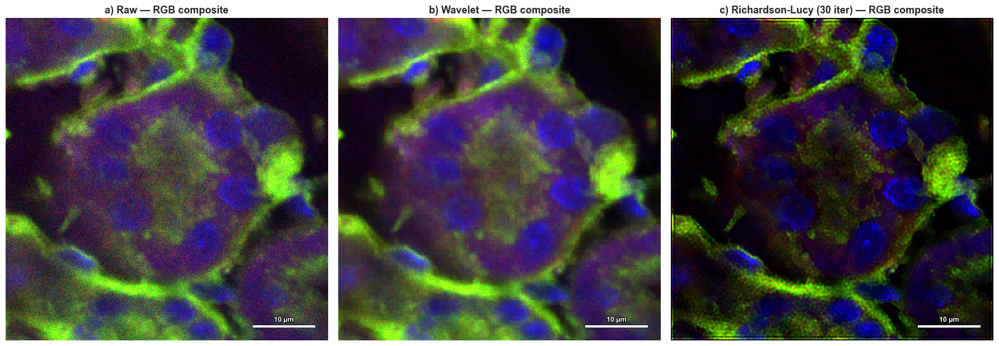

In [7]:
# =============================================================================
# RGB MULTI-CHANNEL MERGING — Raw vs Wavelet vs R-L (AUTO WHITE BALANCE)
# Ch1 -> Blue | Ch2 -> Green | Ch3 -> Red
# =============================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from skimage import img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.exposure import rescale_intensity
from scipy.special import j0

try:
    from numpy import trapezoid
except ImportError:
    from numpy import trapz as trapezoid


# =============================================================================
# Utilities
# =============================================================================



def _norm_percentile(img, lo=0.1, hi=99.9):
    vmin, vmax = np.percentile(img, (lo, hi))
    return rescale_intensity(
        img,
        in_range=(vmin, vmax),
        out_range=(0.0, 1.0),
    )


def make_born_wolf_psf(p, size, n_samples):

    k = 2 * np.pi * p["ni"] / p["wavelength"]

    ax = (np.arange(size) - size // 2) * p["pixel_size"]

    rho = np.linspace(0, 1, n_samples)

    psf = np.zeros((size, size))

    for i, x in enumerate(ax):
        for j, y in enumerate(ax):

            r = np.sqrt(x**2 + y**2)

            integrand = j0(k * p["NA"] * r * rho / p["ni"]) * rho

            psf[i, j] = trapezoid(integrand, rho) ** 2

    psf /= psf.sum()

    return psf


# =============================================================================
# Load channels
# =============================================================================

if "raw_channels" in dir() and len(raw_channels) == 3:

    RAW_CHANNELS_SRC = raw_channels

elif (
    "CONFIG" in dir()
    and all(k in CONFIG for k in ("file_ch1", "file_ch2", "file_ch3"))
):

    from pathlib import Path
    from skimage.io import imread

    RAW_CHANNELS_SRC = []

    for fname in (
        CONFIG["file_ch1"],
        CONFIG["file_ch2"],
        CONFIG["file_ch3"],
    ):

        stack = imread(Path(fname))

        z = CONFIG.get("z_target", 0)

        sl = stack[z] if stack.ndim == 3 else stack

        RAW_CHANNELS_SRC.append(img_as_float(sl))

else:

    raise RuntimeError("Raw channels not found.")


CHANNEL_NAMES = (
    CONFIG["channel_names"]
    if ("channel_names" in CONFIG)
    else ["Channel 1", "Channel 2", "Channel 3"]
)


# =============================================================================
# Single-channel processing
# =============================================================================

def process_channel(raw_c, psf):

    img_ansc = _anscombe(raw_c)

    sigma_est = float(np.mean(restoration.estimate_sigma(img_ansc)))

    img_nlm = restoration.denoise_nl_means(
        img_ansc,
        h=PARAMS["nlm_h_factor"] * sigma_est,
        fast_mode=True,
        patch_size=PARAMS["nlm_patch"],
        patch_distance=PARAMS["nlm_dist"],
    )

    img_denoised = np.clip(_inv_anscombe(img_nlm), 0, None)

    img_bg = white_tophat(
        img_denoised,
        disk(PARAMS["tophat_radius"]),
    )

    img_clean = np.clip(img_bg, 0, None)

    img_rl = restoration.richardson_lucy(
        img_clean,
        psf,
        num_iter=30,
        filter_epsilon=PARAMS["rl_epsilon"],
    )

    img_rl = _norm_percentile(img_rl)

    img_wavelet = restoration.denoise_wavelet(
        raw_c,
        method="BayesShrink",
        mode="soft",
        rescale_sigma=True,
    )

    img_wavelet = _norm_percentile(img_wavelet)

    raw_norm = _norm_percentile(raw_c)

    return raw_norm, img_rl, img_wavelet


# =============================================================================
# White balance (Gray World)
# =============================================================================

def white_balance(rgb):

    gain = rgb.mean(axis=(0, 1))

    gain /= gain.mean()

    rgb = rgb / gain

    rgb = np.clip(rgb, 0, 1)

    return rgb


# =============================================================================
# RGB merge
# =============================================================================

def merge_rgb(channels):

    rgb = np.dstack([
        channels[2],   # Red
        channels[1],   # Green
        channels[0],   # Blue
    ])

    rgb = white_balance(rgb)

    return rgb


# =============================================================================
# Process channels
# =============================================================================

psf = make_born_wolf_psf(
    MICROSCOPE,
    size=PARAMS["psf_size"],
    n_samples=PARAMS["psf_n_samples"],
)

raw_stack = []
wav_stack = []
rl_stack = []

for i, raw in enumerate(RAW_CHANNELS_SRC):

    print(f"Processing {CHANNEL_NAMES[i]}...")

    raw_img, rl_img, wav_img = process_channel(raw, psf)

    raw_stack.append(raw_img)
    wav_stack.append(wav_img)
    rl_stack.append(rl_img)


# =============================================================================
# Merge
# =============================================================================

rgb_raw = merge_rgb(raw_stack)
rgb_wav = merge_rgb(wav_stack)
rgb_rl = merge_rgb(rl_stack)


# =============================================================================
# Plot
# =============================================================================

sns.set_theme(style="white", context="notebook")

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))

titles = [
    "a) Raw — RGB composite",
    "b) Wavelet — RGB composite",
    "c) Richardson-Lucy (30 iter) — RGB composite",
]

for ax, img, title in zip(
    axes,
    [rgb_raw, rgb_wav, rgb_rl],
    titles,
):

    ax.imshow(img)

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
    )

    ax.axis("off")

    add_scalebar(ax, SCALE_PX_PER_UM)


plt.tight_layout()

out_dir = "/Users/francesco/Repositories/noise_images/immagini_rel"

os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(
    out_dir,
    "merge_rgb_raw_wavelet_rl30_balanced.png",
)

plt.savefig(
    out_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

print(f"Saved to {out_path}")

plt.show()

## Phase 5: altro campione

Extracting slice Z=14...
Channels loaded: 3 — shape: (512, 512)


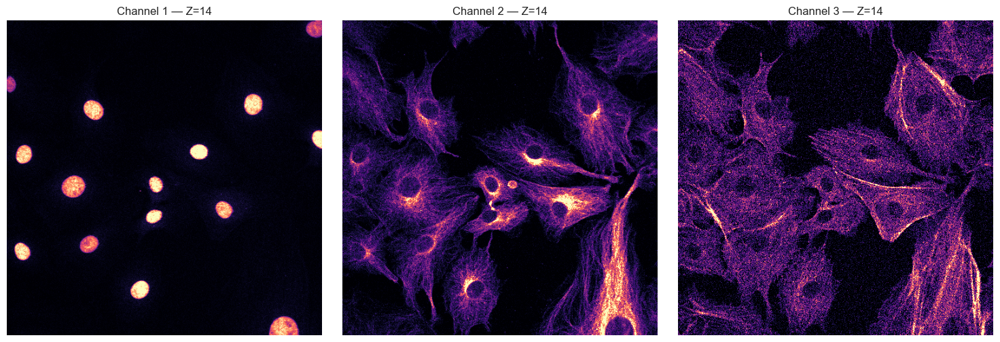

In [8]:
# =============================================================================
# CONFIGURATION — adjust paths and parameters to your dataset
# =============================================================================
CONFIG = {
    "folder_path": "/Users/francesco/Repositories/1.sem/noise_images/immk",
    "file_ch1": "/Users/francesco/Repositories/1.sem/noise_images/immk/cow_19_12_770nm_25mW_5_frames_Ch1.tif",
    "file_ch2": "/Users/francesco/Repositories/1.sem/noise_images/immk/cow_19_12_770nm_25mW_5_frames_Ch2.tif",
    "file_ch3": "/Users/francesco/Repositories/1.sem/noise_images/immk/cow_19_12_770nm_25mW_5_frames_Ch3.tif",
    "channel_names": ["Channel 1", "Channel 2", "Channel 3"],
    "z_target": 13,         # Python index → corresponds to Z=12/50
    "cmap": "magma",
}

# Physical calibration (from ImageJ)
DIST_PX         = 109.0046
DIST_UM         = 31.94
PX_SIZE_UM      = DIST_UM / DIST_PX       # ~0.293 µm/px
SCALE_PX_PER_UM = DIST_PX / DIST_UM       # ~3.41 px/µm

# Pipeline parameters
PARAMS = dict(
    nlm_h          = 0.80,   # NLM filter strength (sigma multiplier)
    tophat_r       = 40,     # White Top-Hat footprint radius (px)
    gauss_bg_sigma = 20,     # Gaussian Subtraction sigma for background estimate
    rl_iters       = 15,     # Richardson-Lucy iterations (see Phase 3 note)
    psf_sigma      = 1.5,    # Gaussian PSF sigma (px)
    psf_size       = 51,     # PSF kernel size (px, must be odd)
)

# =============================================================================
# LOAD Z-STACK AND EXTRACT SLICE Z=12 — all 3 channels
# =============================================================================
os.chdir(CONFIG["folder_path"])

raw_channels = []   # list of 2D float slices, normalised [0, 1]

print(f"Extracting slice Z={CONFIG['z_target'] + 1}...")

for fname in [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]:
    p = Path(fname)
    if not p.exists():
        raise FileNotFoundError(f"File not found: {p.absolute()}")
    stack = io.imread(p)
    sl = stack[CONFIG["z_target"], :, :] if stack.ndim == 3 else stack
    raw_channels.append(img_as_float(sl))

print(f"Channels loaded: {len(raw_channels)} — shape: {raw_channels[0].shape}")

# Working reference: Channel 1
raw = raw_channels[0]

# Quick overview — all 3 channels
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, name in zip(axes, raw_channels, CONFIG["channel_names"]):
    ax.imshow(img, cmap=CONFIG["cmap"], vmax=np.percentile(img, 99.5))
    ax.set_title(f"{name} — Z={CONFIG['z_target'] + 1}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("00_raw_channels.pdf", bbox_inches="tight", facecolor="white")
plt.show()
plt.close("all")

Extracting slice Z=14...
Channels loaded: 3 — shape: (512, 512)
Extracting slice Z=14...
Channels loaded: 3 — shape: (512, 512)


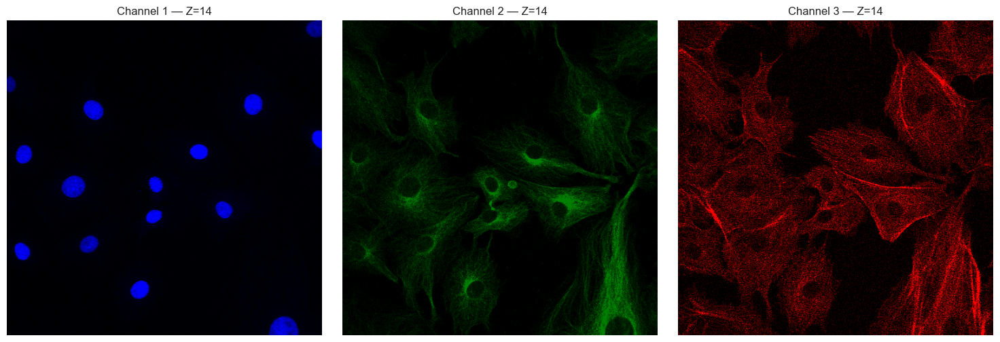

In [9]:
# =============================================================================
# CONFIGURATION — adjust paths and parameters to your dataset
# =============================================================================
CONFIG = {
    "folder_path": "/Users/francesco/Repositories/1.sem/noise_images/immk",
    "file_ch1": "/Users/francesco/Repositories/1.sem/noise_images/immk/cow_19_12_770nm_25mW_5_frames_Ch1.tif",
    "file_ch2": "/Users/francesco/Repositories/1.sem/noise_images/immk/cow_19_12_770nm_25mW_5_frames_Ch2.tif",
    "file_ch3": "/Users/francesco/Repositories/1.sem/noise_images/immk/cow_19_12_770nm_25mW_5_frames_Ch3.tif",
    "channel_names": ["Channel 1", "Channel 2", "Channel 3"],
    "z_target": 13,         # Python index → corresponds to Z=12/50
    "cmap": "magma",
}

# Physical calibration (from ImageJ)
DIST_PX         = 109.0046
DIST_UM         = 31.94
PX_SIZE_UM      = DIST_UM / DIST_PX       # ~0.293 µm/px
SCALE_PX_PER_UM = DIST_PX / DIST_UM       # ~3.41 px/µm

# Pipeline parameters
PARAMS = dict(
    nlm_h          = 0.80,   # NLM filter strength (sigma multiplier)
    tophat_r       = 40,     # White Top-Hat footprint radius (px)
    gauss_bg_sigma = 20,     # Gaussian Subtraction sigma for background estimate
    rl_iters       = 15,     # Richardson-Lucy iterations (see Phase 3 note)
    psf_sigma      = 1.5,    # Gaussian PSF sigma (px)
    psf_size       = 51,     # PSF kernel size (px, must be odd)
)

# =============================================================================
# LOAD Z-STACK AND EXTRACT SLICE Z=12 — all 3 channels
# =============================================================================
os.chdir(CONFIG["folder_path"])

raw_channels = []   # list of 2D float slices, normalised [0, 1]

print(f"Extracting slice Z={CONFIG['z_target'] + 1}...")

for fname in [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]:
    p = Path(fname)
    if not p.exists():
        raise FileNotFoundError(f"File not found: {p.absolute()}")
    stack = io.imread(p)
    sl = stack[CONFIG["z_target"], :, :] if stack.ndim == 3 else stack
    raw_channels.append(img_as_float(sl))

print(f"Channels loaded: {len(raw_channels)} — shape: {raw_channels[0].shape}")

# =============================================================================
# CONFIGURATION — adjust paths and parameters to your dataset
# =============================================================================
CONFIG = {
    "folder_path": "/Users/francesco/Repositories/1.sem/noise_images/immk",
    "file_ch1": "/Users/francesco/Repositories/1.sem/noise_images/immk/cow_19_12_770nm_25mW_5_frames_Ch1.tif",
    "file_ch2": "/Users/francesco/Repositories/1.sem/noise_images/immk/cow_19_12_770nm_25mW_5_frames_Ch2.tif",
    "file_ch3": "/Users/francesco/Repositories/1.sem/noise_images/immk/cow_19_12_770nm_25mW_5_frames_Ch3.tif",
    "channel_names": ["Channel 1", "Channel 2", "Channel 3"],
    "z_target": 13,         # Python index → corresponds to Z=12/50
    "cmap": "magma",
}

# Physical calibration (from ImageJ)
DIST_PX         = 109.0046
DIST_UM         = 31.94
PX_SIZE_UM      = DIST_UM / DIST_PX       # ~0.293 µm/px
SCALE_PX_PER_UM = DIST_PX / DIST_UM       # ~3.41 px/µm

# Pipeline parameters
PARAMS = dict(
    nlm_h          = 0.80,   # NLM filter strength (sigma multiplier)
    tophat_r       = 40,     # White Top-Hat footprint radius (px)
    gauss_bg_sigma = 20,     # Gaussian Subtraction sigma for background estimate
    rl_iters       = 15,     # Richardson-Lucy iterations (see Phase 3 note)
    psf_sigma      = 1.5,    # Gaussian PSF sigma (px)
    psf_size       = 51,     # PSF kernel size (px, must be odd)
)

# =============================================================================
# LOAD Z-STACK AND EXTRACT SLICE Z=12 — all 3 channels
# =============================================================================
os.chdir(CONFIG["folder_path"])

raw_channels = []   # list of 2D float slices, normalised [0, 1]

print(f"Extracting slice Z={CONFIG['z_target'] + 1}...")

for fname in [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]:
    p = Path(fname)
    if not p.exists():
        raise FileNotFoundError(f"File not found: {p.absolute()}")
    stack = io.imread(p)
    sl = stack[CONFIG["z_target"], :, :] if stack.ndim == 3 else stack
    raw_channels.append(img_as_float(sl))

print(f"Channels loaded: {len(raw_channels)} — shape: {raw_channels[0].shape}")

# Working reference: Channel 1
raw = raw_channels[0]
from matplotlib.colors import LinearSegmentedColormap

# =============================================================================
# QUICK OVERVIEW — ALL 3 CHANNELS (RED, GREEN, BLUE)
# =============================================================================

# 1. Definisco le mappe colore (da nero al colore puro)
cmap_red   = LinearSegmentedColormap.from_list("black_red", ["black", "red"])
cmap_green = LinearSegmentedColormap.from_list("black_green", ["black", "green"])
cmap_blue  = LinearSegmentedColormap.from_list("black_blue", ["black", "blue"])

# 2. Le inserisco in una lista che seguirà l'ordine dei tuoi canali
channel_cmaps = [cmap_blue, cmap_green, cmap_red]

# 3. Disegno i plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Aggiungo 'channel_cmaps' allo zip per iterare sulle mappe colore
for ax, img, name, cmap in zip(axes, raw_channels, CONFIG["channel_names"], channel_cmaps):
    # Uso la mappa colore specifica del canale invece di CONFIG["cmap"]
    ax.imshow(img, cmap=cmap, vmax=np.percentile(img, 99.5))
    ax.set_title(f"{name} — Z={CONFIG['z_target'] + 1}")
    ax.axis("off")

plt.tight_layout()
plt.savefig("00_raw_channels.pdf", bbox_inches="tight", facecolor="white")
plt.show()
plt.close("all")

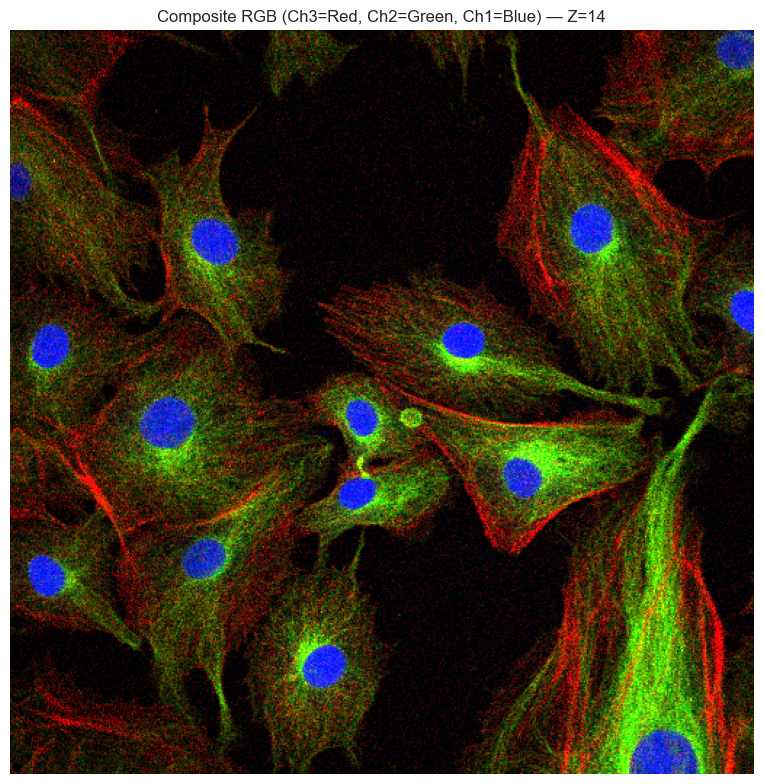

In [10]:
# =============================================================================
# MERGE CHANNELS (COMPOSITE RGB) — FIJI STYLE
# =============================================================================

# Otteniamo le dimensioni dell'immagine
h, w = raw_channels[0].shape

# Inizializziamo un'immagine RGB vuota (H, W, 3) a 0 (nero)
rgb_composite = np.zeros((h, w, 3), dtype=np.float32)

# Basandoci sul tuo ordine (Ch1=Blu, Ch2=Verde, Ch3=Rosso):
# Mappiamo ai corretti indici RGB (0=Rosso, 1=Verde, 2=Blu)
channel_to_rgb_idx = [2, 1, 0] 

for ch_img, rgb_idx in zip(raw_channels, channel_to_rgb_idx):
    # Simuliamo il contrasto automatico di Fiji al 99.5%
    vmax = np.percentile(ch_img, 99.5)
    
    # Dividiamo per vmax in modo che i valori arrivino a 1, e clippiamo tra 0 e 1
    # per evitare valori fuori scala causati dai pixel più luminosi del vmax
    ch_norm = np.clip(ch_img / vmax, 0, 1)
    
    # Assegniamo il canale normalizzato alla rispettiva "fetta" di colore nell'RGB
    rgb_composite[:, :, rgb_idx] = ch_norm

# Plot dell'immagine composita
fig, ax = plt.subplots(figsize=(8, 8))

# Matplotlib interpreta automaticamente le matrici (H, W, 3) come immagini RGB
ax.imshow(rgb_composite)
ax.set_title(f"Composite RGB (Ch3=Red, Ch2=Green, Ch1=Blue) — Z={CONFIG['z_target'] + 1}")
ax.axis("off")

plt.tight_layout()
plt.savefig("01_composite_channels.pdf", bbox_inches="tight", facecolor="white")
plt.show()
plt.close("all")